# Tabular — Analisis Survival
**Kapan dipakai:** kita ingin menebak KAPAN sebuah kejadian (event) terjadi, misalnya
pelanggan berhenti, mesin rusak, pasien kambuh. Sebagian data belum mengalami event saat
pengamatan selesai (disebut "censored"), jadi regresi biasa tidak cocok.

**Dua kolom wajib:** durasi (berapa lama diamati) dan event (1 = terjadi, 0 = belum).

**Metrik:** C-index (1.0 = urutan risiko sempurna, 0.5 = acak).
Submission = skor risiko (makin besar = makin cepat event).

**Data demo:** Rossi (`week` = minggu sejak bebas penjara, `arrest` = ditangkap lagi 1/0).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from lifelines import CoxPHFitter, KaplanMeierFitter, LogNormalAFTFitter, WeibullAFTFitter
from lifelines import LogLogisticAFTFitter
from lifelines.utils import concordance_index
from sklearn.model_selection import train_test_split

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/tabular_extra/survival"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/rossi_train.csv"
TEST_CSV = f"{DATA_FOLDER}/rossi_test.csv"

DURATION = "week"      # kolom lama pengamatan
EVENT = "arrest"       # kolom event (1 = terjadi, 0 = belum)
FEATURES = ["fin", "age", "race", "wexp", "mar", "paro", "prio"]
GROUP_COL = "fin"      # kolom untuk membandingkan kurva Kaplan-Meier
SEED = 42

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
missing_per_column = train.isna().sum()
print("sel kosong:", missing_per_column.sum())
train.head()

train: (324, 10) | test: (108, 8)
sel kosong: 0


,id,week,arrest,fin,age,race,wexp,mar,paro,prio
0,388,26,1,0,22,1,0,1,1,2
1,7,23,1,0,25,1,1,1,1,0
2,297,52,0,1,22,1,1,0,1,3
3,47,52,0,1,22,1,0,0,0,15
4,375,52,0,0,31,1,0,0,1,1


## EDA — kurva Kaplan-Meier
Sumbu y = peluang belum mengalami event sampai waktu x. Kurva yang turun lebih cepat =
kelompok yang lebih cepat mengalami event.

proporsi event: 0.262


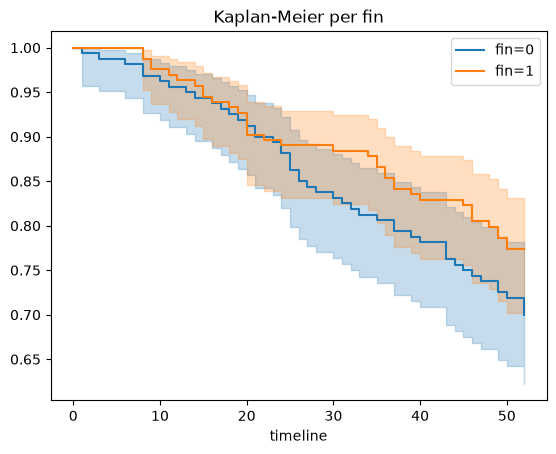

In [4]:
print("proporsi event:", round(train[EVENT].mean(), 3))

kmf = KaplanMeierFitter()
for value, group in train.groupby(GROUP_COL):
    kmf.fit(group[DURATION], group[EVENT], label=f"{GROUP_COL}={value}")
    kmf.plot_survival_function()
plt.title(f"Kaplan-Meier per {GROUP_COL}")
plt.show()

## Split train / validasi

In [5]:
train_part, val_part = train_test_split(train, test_size=0.25, random_state=SEED)

## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai, beri `#` pada baris lain.
- Cox: menebak risiko relatif.
- AFT (Weibull, LogNormal, LogLogistic): menebak waktu sampai event.

In [6]:
model = CoxPHFitter(penalizer=0.1)
# model = WeibullAFTFitter(penalizer=0.1)
# model = LogNormalAFTFitter(penalizer=0.1)
# model = LogLogisticAFTFitter(penalizer=0.1)
# model = CoxPHFitter(penalizer=0.1, l1_ratio=0.5)
# model = CoxPHFitter(penalizer=0.01)

model.fit(train_part[FEATURES + [DURATION, EVENT]], duration_col=DURATION, event_col=EVENT)
model.print_summary(decimals=3)

<lifelines.CoxPHFitter: fitted with 243 total observations, 179 right-censored observations>
             duration col = 'week'
                event col = 'arrest'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 243
number of events observed = 64
   partial log-likelihood = -333.370
         time fit was run = 2026-10-19 12:54:50 UTC

---
            coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                   
fin       -0.233     0.792     0.215          -0.655           0.188               0.519               1.207
age       -0.037     0.963     0.020          -0.077           0.002               0.926               1.002
race      -0.019     0.981     0.302          -0.612           0.573               0.542               1.774
wexp      -0.179     0.836     0.225          -0.620           0.262               0.538               1.300
mar       -0.471     0.624     0.370          -1.197           0.255               0.302               1.290
paro      -0.006     0.994     0.220          -0.437           0.426               0.646               1.531
prio       0.092     1.097     0.031           0.031           0.153               1.032               1.166

           cmp to      z     p  -log2(p)
covariate                               
fin         0.000 -1.085 0.278     1.848
age         0.000 -1.864 0.062     4.004
race        0.000 -0.064 0.949     0.075
wexp        0.000 -0.794 0.427     1.227
mar         0.000 -1.272 0.203     2.299
paro        0.000 -0.026 0.979     0.030
prio        0.000  2.973 0.003     8.407
---
Concordance = 0.658
Partial AIC = 680.740
log-likelihood ratio test = 18.109 on 7 df
-log2(p) of ll-ratio test = 6.444

## Evaluasi di validasi
Cox memberi risiko (`predict_partial_hazard`). AFT memberi waktu (`predict_median`), jadi
risikonya = minus waktu. Kalau memakai model AFT, pindahkan `#` ke baris pertama.
`concordance_index` meminta "makin besar = makin lama hidup", jadi risikonya diberi minus.

In [7]:
val_risk = model.predict_partial_hazard(val_part[FEATURES])
# val_risk = -model.predict_median(val_part[FEATURES])
c_index = concordance_index(val_part[DURATION], -val_risk, val_part[EVENT])
print("C-index:", round(c_index, 4))

C-index: 0.6201


## Latih ulang di semua data + submission

In [8]:
model.fit(train[FEATURES + [DURATION, EVENT]], duration_col=DURATION, event_col=EVENT)
predictions = model.predict_partial_hazard(test[FEATURES])
# predictions = -model.predict_median(test[FEATURES])

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["risk"] = predictions.values
submission.to_csv("submission.csv", index=False)
submission.head()

,id,risk
0,120,1.213057
1,383,0.793817
2,366,1.101377
3,415,1.165768
4,193,0.693841
